In [1]:
#Kết nối GGDrive
from google.colab import drive
drive.mount('/content/drive')

PROJECT_DIR = '/content/drive/MyDrive/SIC AI 2026/Fall-detection-v2'
import os
os.makedirs(PROJECT_DIR, exist_ok=True)

Mounted at /content/drive


In [2]:
#Upload kaggle.json và tải dataset:
from google.colab import files
files.upload()  # chọn kaggle.json từ máy bạn

!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

# Tải và giải nén bộ dữ liệu URFD vào ổ SSD tạm của Colab (/content/dataset_raw)
print("\n[*] Đang tải dữ liệu từ Kaggle...")
!kaggle datasets download -d shahliza27/ur-fall-detection-dataset
print("[*] Đang giải nén dữ liệu...")
!unzip -q ur-fall-detection-dataset.zip -d /content/dataset_raw
print("[+] Giải nén hoàn tất!")


Saving kaggle.json to kaggle.json

[*] Đang tải dữ liệu từ Kaggle...
Dataset URL: https://www.kaggle.com/datasets/shahliza27/ur-fall-detection-dataset
License(s): unknown
100% 4.18G/4.18G [04:19<00:00, 17.3MB/s]

[*] Đang giải nén dữ liệu...
[+] Giải nén hoàn tất!


#Cài đặt thư viện

In [3]:
!pip install ultralytics opencv-python-headless numpy torch gdown

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.5/45.5 kB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 75.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.4/61.4 kB 6.6 MB/s eta 0:00:00


In [4]:
# --- CELL 2: KHAI BÁO THƯ VIỆN VÀ CẤU HÌNH ---
import os
import cv2
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
from collections import defaultdict
SEQUENCE_LENGTH = 30  # Số khung hình liên tiếp trong 1 chuỗi đưa vào LSTM
INPUT_SIZE = 34       # 17 keypoints x 2 (x, y) = 34 đặc trưng
BATCH_SIZE = 32
EPOCHS = 40
LEARNING_RATE = 0.001
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"[*] Đang sử dụng thiết bị: {DEVICE}")

[*] Đang sử dụng thiết bị: cuda


In [5]:
# --- CELL 3: HÀM CHUẨN HÓA KEYPOINTS ---
def normalize_keypoints(keypoints, bbox=None):
    default_output = np.zeros(34, dtype=np.float32)
    if keypoints is None:
        return default_output
    kp_l_shoulder = keypoints[5]
    kp_r_shoulder = keypoints[6]
    kp_l_hip = keypoints[11]
    kp_r_hip = keypoints[12]
    if (kp_l_shoulder[2] > 0.5 and kp_r_shoulder[2] > 0.5 and
        kp_l_hip[2] > 0.5 and kp_r_hip[2] > 0.5):

        mid_shoulder = np.array([(kp_l_shoulder[0] + kp_r_shoulder[0]) / 2.0,
                                 (kp_l_shoulder[1] + kp_r_shoulder[1]) / 2.0])
        mid_hip = np.array([(kp_l_hip[0] + kp_r_hip[0]) / 2.0,
                             (kp_l_hip[1] + kp_r_hip[1]) / 2.0])

        body_length = np.linalg.norm(mid_hip - mid_shoulder)
        if body_length < 1.0:
            body_length = 1.0
        normalized = []
        for kp in keypoints:
            x, y, _ = kp
            norm_x = (x - mid_hip[0]) / body_length
            norm_y = (y - mid_hip[1]) / body_length
            normalized.extend([norm_x, norm_y])

        return np.array(normalized, dtype=np.float32)
    elif bbox is not None:
        x1, y1, x2, y2 = bbox
        width = x2 - x1
        height = max(y2 - y1, 1.0)
        center_x = (x1 + x2) / 2.0
        center_y = (y1 + y2) / 2.0

        normalized = []
        for kp in keypoints:
            x, y, _ = kp
            norm_x = (x - center_x) / max(width, 1.0)
            norm_y = (y - center_y) / height
            normalized.extend([norm_x, norm_y])
        return np.array(normalized, dtype=np.float32)
    return default_output

In [6]:
# --- CELL 4: PHÂN NHÓM ẢNH THEO CHUỖI VIDEO VÀ TRÍCH XUẤT KEYPOINTS ---
def prepare_dataset_from_images(raw_dir):
    """
    Quét qua thư mục giải nén, nhóm các file ảnh PNG/JPG theo chuỗi video dựa trên tên file.
    Cấu trúc tên file mẫu: adl-16-cam0-rgb-037.png hoặc fall-01-cam0-rgb-001.png
    """
    from ultralytics import YOLO
    print("[*] Đang tải mô hình YOLOv8-Pose trên Colab...")
    yolo_model = YOLO("yolov8n-pose.pt")

    # 1. Nhóm các file ảnh theo khóa video duy nhất
    # Key: "adl-16-cam0" hoặc "fall-01-cam0"
    # Value: Danh sách tuple (frame_id, full_image_path)
    video_groups = defaultdict(list)

    print("[*] Đang phân tích cấu trúc file ảnh...")
    for root, dirs, files_list in os.walk(raw_dir):
        for file in files_list:
            if file.lower().endswith(('.png', '.jpg', '.jpeg')):
                # Tách tên file: ví dụ 'adl-16-cam0-rgb-037.png'
                parts = file.split('-')
                if len(parts) >= 5:
                    action = parts[0]      # 'adl' hoặc 'fall'
                    video_num = parts[1]   # '16'
                    cam = parts[2]         # 'cam0'
                    # parts[4] = '037.png'
                    try:
                        frame_id = int(parts[4].split('.')[0])
                        group_key = f"{action}-{video_num}-{cam}"
                        file_path = os.path.join(root, file)
                        video_groups[group_key].append((frame_id, file_path))
                    except ValueError:
                        continue

    print(f"[+] Tìm thấy {len(video_groups)} chuỗi hành động (video) độc lập.")

    X = []
    y = []

    # 2. Duyệt qua từng nhóm video, sắp xếp theo frame_id và trích xuất keypoints
    group_idx = 0
    for group_key, items in video_groups.items():
        group_idx += 1
        # Sắp xếp các frame theo đúng thứ tự thời gian tăng dần
        items.sort(key=lambda x: x[0])

        # Nhãn: 1 nếu là fall, 0 nếu là adl (hoạt động bình thường)
        label = 1 if "fall" in group_key.lower() else 0

        print(f"[{group_idx}/{len(video_groups)}] Đang trích xuất keypoints chuỗi: {group_key} ({len(items)} frames)...")

        # Trích xuất keypoints của từng ảnh trong nhóm
        seq_kps = []
        for _, img_path in items:
            frame = cv2.imread(img_path)
            if frame is None:
                seq_kps.append(np.zeros(34, dtype=np.float32))
                continue

            results = yolo_model(frame, conf=0.5, verbose=False)
            if len(results) > 0 and len(results[0].boxes) > 0:
                result = results[0]
                boxes = result.boxes.cpu().numpy()
                keypoints_data = result.keypoints.data.cpu().numpy()

                # Tìm người có diện tích box lớn nhất
                max_area = 0
                best_idx = 0
                for idx, box in enumerate(boxes):
                    x1, y1, x2, y2 = box.xyxy[0]
                    area = (x2 - x1) * (y2 - y1)
                    if area > max_area:
                        max_area = area
                        best_idx = idx

                kps = keypoints_data[best_idx]
                bbox = boxes[best_idx].xyxy[0].tolist()
                norm_kps = normalize_keypoints(kps, bbox)
                seq_kps.append(norm_kps)
            else:
                # Nếu không detect được, điền mảng 0 để giữ tính liên tục thời gian
                seq_kps.append(np.zeros(34, dtype=np.float32))

        # 3. Tạo các chuỗi con bằng Sliding Window (độ dài 30 frames, bước nhảy = 5)
        stride = 5
        if len(seq_kps) >= SEQUENCE_LENGTH:
            for i in range(0, len(seq_kps) - SEQUENCE_LENGTH + 1, stride):
                seq = seq_kps[i : i + SEQUENCE_LENGTH]
                X.append(seq)
                y.append(label)

    return np.array(X, dtype=np.float32), np.array(y, dtype=np.float32)

In [7]:
# --- CELL 5: ĐỊNH NGHĨA PYTORCH DATASET & LSTM MODEL ---
class FallDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32).unsqueeze(1)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]
class FallDetectionLSTM(nn.Module):
    def __init__(self, input_size=34, hidden_size=64, num_layers=2, num_classes=1):
        super(FallDetectionLSTM, self).__init__()
        self.hidden_size = hidden_size
        self.num_layers = num_layers

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=0.3 if num_layers > 1 else 0.0
        )

        self.fc = nn.Sequential(
            nn.Linear(hidden_size, 32),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(32, num_classes)
        )
    def forward(self, x):
        h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size).to(x.device)
        c0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size).to(x.device)
        out, _ = self.lstm(x, (h0, c0))
        out = self.fc(out[:, -1, :])
        return out


In [8]:
# --- CELL 6: VÒNG LẶP HUẤN LUYỆN (TRAINING LOOP) ---
def train_model(model, train_loader, val_loader, criterion, optimizer, epochs, device):
    train_losses = []
    val_losses = []
    train_accs = []
    val_accs = []

    best_val_loss = float('inf')

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        correct = 0
        total = 0

        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * inputs.size(0)

            preds = (outputs > 0.0).float()
            correct += (preds == labels).sum().item()
            total += labels.size(0)

        epoch_train_loss = running_loss / len(train_loader.dataset)
        epoch_train_acc = correct / total

        # Validation Phase
        model.eval()
        val_running_loss = 0.0
        val_correct = 0
        val_total = 0

        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)

                val_running_loss += loss.item() * inputs.size(0)
                preds = (outputs > 0.0).float()
                val_correct += (preds == labels).sum().item()
                val_total += labels.size(0)

        epoch_val_loss = val_running_loss / len(val_loader.dataset)
        epoch_val_acc = val_correct / val_total

        train_losses.append(epoch_train_loss)
        val_losses.append(epoch_val_loss)
        train_accs.append(epoch_train_acc)
        val_accs.append(epoch_val_acc)

        print(f"Epoch {epoch+1:02d}/{epochs:02d} | "
              f"Train Loss: {epoch_train_loss:.4f} Acc: {epoch_train_acc:.4f} | "
              f"Val Loss: {epoch_val_loss:.4f} Acc: {epoch_val_acc:.4f}")

        if epoch_val_loss < best_val_loss:
            best_val_loss = epoch_val_loss
            torch.save(model.state_dict(), "best_fall_lstm.pth")
            print("[+] Đã lưu trọng số mô hình tốt nhất: best_fall_lstm.pth")

    torch.save(model.state_dict(), "final_fall_lstm.pth")
    return train_losses, val_losses, train_accs, val_accs


In [9]:
# --- CELL 7: KHỞI CHẠY HUẤN LUYỆN VÀ ĐÁNH GIÁ ---
if __name__ == "__main__":
    raw_dataset_path = "/content/dataset_raw"

    # Kiểm tra xem thực sự có dữ liệu ảnh được giải nén không
    has_real_images = False
    if os.path.exists(raw_dataset_path):
        all_pngs = []
        for root, dirs, files in os.walk(raw_dataset_path):
            for file in files:
                if file.lower().endswith(('.png', '.jpg', '.jpeg')):
                    all_pngs.append(file)
        if len(all_pngs) > 0:
            has_real_images = True
            print(f"[+] Tìm thấy dữ liệu thật: {len(all_pngs)} file ảnh PNG/JPG.")
    # Phân luồng xử lý: dùng dữ liệu thật hoặc tạo dữ liệu giả lập để test code
    if not has_real_images:
        print("[!] Không tìm thấy dữ liệu ảnh thật trong /content/dataset_raw. Đang tạo dữ liệu giả lập (Dummy Data) để chạy test luồng huấn luyện...")
        X_data = np.random.randn(200, SEQUENCE_LENGTH, INPUT_SIZE).astype(np.float32)
        y_data = np.random.randint(0, 2, size=(200,)).astype(np.float32)
        print(f"[+] Khởi tạo thành công Dummy Data: X shape {X_data.shape}, y shape {y_data.shape}")
    else:
        # Nếu có ảnh thật, tiến hành phân nhóm và trích xuất keypoints
        X_data, y_data = prepare_dataset_from_images(raw_dataset_path)
        print(f"[+] Trích xuất dữ liệu thật thành công: X shape {X_data.shape}, y shape {y_data.shape}")

    if len(X_data) == 0:
        print("[!] Lỗi: Không trích xuất được chuỗi nào từ dữ liệu ảnh! Chuyển sang tạo dummy data...")
        X_data = np.random.randn(200, SEQUENCE_LENGTH, INPUT_SIZE).astype(np.float32)
        y_data = np.random.randint(0, 2, size=(200,)).astype(np.float32)
    # Phân chia tập Train/Val/Test
    X_train, X_temp, y_train, y_temp = train_test_split(X_data, y_data, test_size=0.3, random_state=42, stratify=y_data)
    X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)

    # Khởi tạo DataLoader
    train_dataset = FallDataset(X_train, y_train)
    val_dataset = FallDataset(X_val, y_val)
    test_dataset = FallDataset(X_test, y_test)

    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
    test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

    # Khởi tạo Mô hình, Optimizer, Loss Function
    model = FallDetectionLSTM(input_size=INPUT_SIZE, hidden_size=64, num_layers=2, num_classes=1).to(DEVICE)


    # Thay phần criterion bằng đoạn này
    pos_weight = torch.tensor([2.0], dtype=torch.float32).to(DEVICE)
    print(f"[*] Class weight (Fall): {pos_weight.item():.2f}x")
    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

    optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)

    # Bắt đầu training
    print("[*] Bắt đầu quá trình huấn luyện...")
    train_losses, val_losses, train_accs, val_accs = train_model(
        model, train_loader, val_loader, criterion, optimizer, EPOCHS, DEVICE
    )

[+] Tìm thấy dữ liệu thật: 11936 file ảnh PNG/JPG.
Creating new Ultralytics Settings v0.0.7 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
[*] Đang tải mô hình YOLOv8-Pose trên Colab...
[*] Đang phân tích cấu trúc file ảnh...
[+] Tìm thấy 70 chuỗi hành động (video) độc lập.
[1/70] Đang trích xuất keypoints chuỗi: fall-14-cam0 (61 frames)...
[2/70] Đang trích xuất keypoints chuỗi: adl-38-cam0 (345 frames)...
[3/70] Đang trích xuất keypoints chuỗi: adl-14-cam0 (235 frames)...
[4/70] Đang trích xuất keypoints chuỗi: fall-26-cam0 (61 frames)...
[5/70] Đang trích xuất keypoints chuỗi: adl-05-cam0 (180 frames)...
[6/70] Đang trích xuất keypoints chuỗi: adl-27-cam0 (100 frames)...
[7/70] Đang trích xuất keypoints chuỗi: adl-03-cam0 (180 frames)...
[8/70] Đang trích xuất key

[*] Đang đánh giá mô hình trên tập Test...

[*] Đang tìm ngưỡng phân loại tối ưu trên tập Validation...
 Threshold | Recall-Fall | Precision-Fall |  F1-Fall
----------------------------------------------------
      0.20 |       0.985 |          0.541 |    0.698
      0.25 |       0.985 |          0.555 |    0.710
      0.30 |       0.970 |          0.591 |    0.734
      0.35 |       0.955 |          0.610 |    0.744
      0.40 |       0.910 |          0.678 |    0.777
      0.45 |       0.866 |          0.707 |    0.779
      0.50 |       0.836 |          0.757 |    0.794
      0.55 |       0.806 |          0.818 |    0.812
      0.60 |       0.791 |          0.883 |    0.835
      0.65 |       0.731 |          0.891 |    0.803

[+] Ngưỡng tối ưu tìm được: 0.60 (F1-Fall trên Val: 0.835)

--- BÁO CÁO KẾT QUẢ ĐÁNH GIÁ (Classification Report) ---
              precision    recall  f1-score   support

      Normal       0.94      0.98      0.96       239
        Fall       0.91      0.79

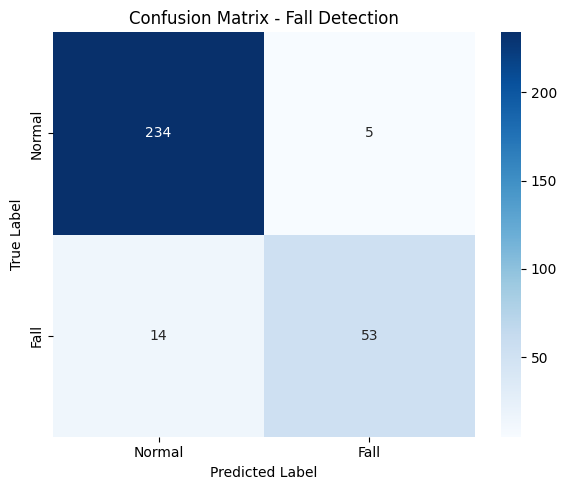

[+] Đã sao lưu bản copy mô hình tốt nhất vào Google Drive tại: /content/drive/MyDrive/SIC AI 2026/Fall-detection-v2/best_fall_lstm.pth


In [11]:
# --- CELL 8: TÌM NGƯỠNG TỐI ƯU + ĐÁNH GIÁ TRÊN TẬP TEST ---
import numpy as np
import seaborn as sns
from sklearn.metrics import f1_score, classification_report, confusion_matrix

print("[*] Đang đánh giá mô hình trên tập Test...")
model.load_state_dict(torch.load("best_fall_lstm.pth"))
model.eval()

# Bước 1: Thu thập xác suất dự đoán trên tập VALIDATION để tìm ngưỡng tối ưu
val_probs = []
val_true  = []
with torch.no_grad():
    for inputs, labels in val_loader:
        inputs = inputs.to(DEVICE)
        outputs = model(inputs)
        probs = torch.sigmoid(outputs)
        val_probs.extend(probs.cpu().numpy().flatten())
        val_true.extend(labels.numpy().flatten())

val_probs = np.array(val_probs)
val_true  = np.array(val_true)

# Bước 2: Thử các ngưỡng từ 0.1 đến 0.9, chọn ngưỡng có F1-Fall cao nhất
best_threshold = 0.5
best_f1_fall   = 0.0

print("\n[*] Đang tìm ngưỡng phân loại tối ưu trên tập Validation...")
print(f"{'Threshold':>10} | {'Recall-Fall':>11} | {'Precision-Fall':>14} | {'F1-Fall':>8}")
print("-" * 52)

for thresh in np.arange(0.20, 0.70, 0.05):
    preds = (val_probs > thresh).astype(float)
    # Tránh lỗi khi tất cả dự đoán là 1 lớp
    if len(np.unique(preds)) < 2:
        continue
    f1_fall = f1_score(val_true, preds, pos_label=1, zero_division=0)
    recall_fall = (preds[val_true == 1] == 1).mean()
    prec_fall   = (val_true[preds == 1] == 1).mean() if (preds == 1).sum() > 0 else 0
    print(f"{thresh:>10.2f} | {recall_fall:>11.3f} | {prec_fall:>14.3f} | {f1_fall:>8.3f}")
    if f1_fall > best_f1_fall:
        best_f1_fall  = f1_fall
        best_threshold = thresh

print(f"\n[+] Ngưỡng tối ưu tìm được: {best_threshold:.2f} (F1-Fall trên Val: {best_f1_fall:.3f})")

# Bước 3: Áp dụng ngưỡng tối ưu đó lên tập TEST để đánh giá cuối cùng
test_probs = []
test_true  = []
with torch.no_grad():
    for inputs, labels in test_loader:
        inputs = inputs.to(DEVICE)
        outputs = model(inputs)
        probs = torch.sigmoid(outputs)
        test_probs.extend(probs.cpu().numpy().flatten())
        test_true.extend(labels.numpy().flatten())

test_probs = np.array(test_probs)
test_true  = np.array(test_true)
test_preds = (test_probs > best_threshold).astype(float)

print("\n--- BÁO CÁO KẾT QUẢ ĐÁNH GIÁ (Classification Report) ---")
print(classification_report(test_true, test_preds, target_names=["Normal", "Fall"]))

print("--- MA TRẬN NHẦM LẪN (Confusion Matrix) ---")


# Tính confusion matrix
cm = confusion_matrix(test_true, test_preds)

# Vẽ confusion matrix
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,          # Hiển thị số trên từng ô
    fmt='d',             # Hiển thị số nguyên
    cmap='Blues',
    xticklabels=['Normal', 'Fall'],
    yticklabels=['Normal', 'Fall']
)

plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix - Fall Detection')

plt.tight_layout()
plt.show()


# Sao lưu mô hình vào Google Drive để tránh bị mất
PROJECT_DIR = '/content/drive/MyDrive/SIC AI 2026/Fall-detection-v2'

if os.path.exists(PROJECT_DIR):
    import shutil

    drive_model_path = os.path.join(
        PROJECT_DIR,
        "best_fall_lstm.pth"
    )

    shutil.copy(
        "best_fall_lstm.pth",
        drive_model_path
    )

    print(
        f"[+] Đã sao lưu bản copy mô hình tốt nhất vào Google Drive tại: "
        f"{drive_model_path}"
    )

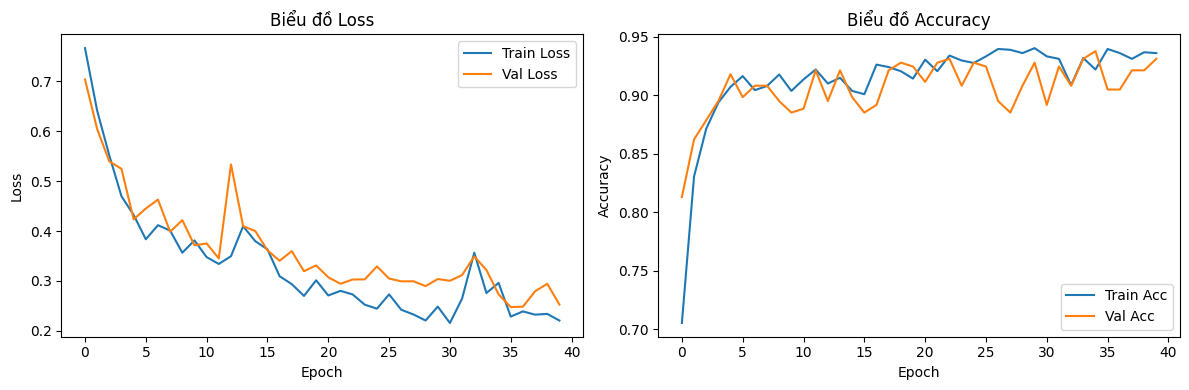

[+] Biểu đồ kết quả đã được lưu tại: training_results.png


In [12]:
# --- CELL 9: VẼ BIỂU ĐỒ LOSS & ACCURACY ---
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(train_losses, label="Train Loss")
plt.plot(val_losses, label="Val Loss")
plt.title("Biểu đồ Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(train_accs, label="Train Acc")
plt.plot(val_accs, label="Val Acc")
plt.title("Biểu đồ Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.tight_layout()
plt.savefig("training_results.png")
plt.show()
print("[+] Biểu đồ kết quả đã được lưu tại: training_results.png")